<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E8%A9%95%E4%BC%B0%E6%8C%87%E6%A8%99/accuracy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 準確率 (Accuracy)

> **一句話記住**：準確率 = **猜對的題數 ÷ 總題數**，就像考試的「答對率」。

📚 [回到評估指標總覽](./README.md)

## 🎯 學完這份筆記本，你會…
- 手算與用 `sklearn` 算出準確率
- 理解**「準確率 95% 的模型可能完全沒用」**這個經典陷阱

---

## 📐 公式

$$\text{Accuracy} = \frac{\text{猜對的}}{\text{全部}} = \frac{TP + TN}{TP + TN + FP + FN}$$

**白話讀法**：混淆矩陣中，「綠色對角線」佔全部的比例。

| 準確率 | 意義 |
| :---: | :--- |
| 1.0 (100%) | 每一題都猜對 |
| 0.8 (80%) | 10 題猜對 8 題 |
| 0.5 (50%) | 跟丟硬幣差不多（兩類各半時） |

---
### 【步驟 0】環境準備：載入套件與中文字型

> 這一格只要**按執行**就好，不用看懂。它會幫你安裝中文字型，讓圖表上的中文不會變成 □□□。

In [1]:
# 【步驟 0】載入套件與設定中文字型（Colab / Mac / Windows 通用）
import os, glob, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import mplfonts
except ImportError:  # Colab 第一次執行時自動安裝
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mplfonts"])
    import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")

# 統一圖表風格：去掉上、右邊框，讓畫面更乾淨
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "figure.dpi": 100,
})
BLUE, GREEN, RED, ORANGE, PURPLE, GRAY = "#3182ce", "#38a169", "#e53e3e", "#dd6b20", "#805ad5", "#a0aec0"

print("✅ 套件與中文字型載入完成！")

✅ 套件與中文字型載入完成！


---
### 【步驟 1】準備資料：垃圾信過濾器判斷 10 封信

`1` = 垃圾信、`0` = 正常信

In [2]:
# 學生可以透過 prompt: "定義垃圾郵件檢測情境的真實標籤 y_true 與預測標籤 y_pred，並用 DataFrame 標示每封信是否猜對"
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]  # 實際：1=垃圾信、0=正常信
y_pred = [1, 0, 1, 0, 0, 0, 1, 1, 1, 0]  # 模型的預測

df = pd.DataFrame({
    "信件": [f"第{i+1}封" for i in range(10)],
    "實際": ["垃圾" if t else "正常" for t in y_true],
    "預測": ["垃圾" if p else "正常" for p in y_pred],
    "猜對了嗎": ["✅" if t == p else "❌" for t, p in zip(y_true, y_pred)],
})
display(df)

,信件,實際,預測,猜對了嗎
0,第1封,垃圾,垃圾,✅
1,第2封,正常,正常,✅
2,第3封,垃圾,垃圾,✅
3,第4封,垃圾,正常,❌
4,第5封,正常,正常,✅
5,第6封,正常,正常,✅
6,第7封,垃圾,垃圾,✅
7,第8封,正常,垃圾,❌
8,第9封,垃圾,垃圾,✅
9,第10封,正常,正常,✅


---
### 【步驟 2】手算準確率，再用 sklearn 驗證

In [3]:
# 學生可以透過 prompt: "計算 TP、TN、FP、FN，依公式 (TP+TN)/全部 手算準確率，並用 sklearn 的 accuracy_score 驗證"
from sklearn.metrics import accuracy_score

TP = sum((t == 1 and p == 1) for t, p in zip(y_true, y_pred))
FN = sum((t == 1 and p == 0) for t, p in zip(y_true, y_pred))
FP = sum((t == 0 and p == 1) for t, p in zip(y_true, y_pred))
TN = sum((t == 0 and p == 0) for t, p in zip(y_true, y_pred))

accuracy = (TP + TN) / (TP + TN + FP + FN)

print(f"TP={TP}, TN={TN}, FP={FP}, FN={FN}")
print(f"猜對 {TP + TN} 封 / 總共 {len(y_true)} 封")
print(f"📝 手算準確率      ：{accuracy:.2f}")
print(f"🤖 sklearn 準確率 ：{accuracy_score(y_true, y_pred):.2f}")

TP=4, TN=4, FP=1, FN=1
猜對 8 封 / 總共 10 封
📝 手算準確率      ：0.80
🤖 sklearn 準確率 ：0.80


#### 👀 看懂結果
10 封信猜對 8 封，準確率 **0.80 (80%)**。錯的 2 封分別是：第 4 封垃圾信沒擋到 (FN)、第 8 封正常信被誤擋 (FP)。

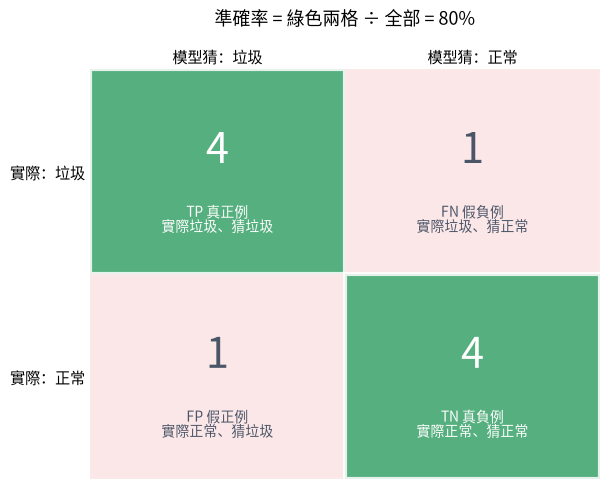

In [4]:
# 🛠️ 畫圖小工具：畫出「好讀版」混淆矩陣（不用背，會用就好）
def draw_confusion(TP, FN, FP, TN, pos="正類", neg="負類", highlight=None, title="混淆矩陣"):
    """highlight 可傳入要強調的格子，例如 ["TP", "FP"]；其他格子會變淡。"""
    cells = {
        "TP": (0, 0, TP, f"TP 真正例\n實際{pos}、猜{pos}", GREEN),
        "FN": (0, 1, FN, f"FN 假負例\n實際{pos}、猜{neg}", RED),
        "FP": (1, 0, FP, f"FP 假正例\n實際{neg}、猜{pos}", RED),
        "TN": (1, 1, TN, f"TN 真負例\n實際{neg}、猜{neg}", GREEN),
    }
    fig, ax = plt.subplots(figsize=(6.2, 5))
    for key, (r, c, n, label, color) in cells.items():
        alpha = 0.85 if (highlight is None or key in highlight) else 0.12
        ax.add_patch(plt.Rectangle((c, 1 - r), 1, 1, color=color, alpha=alpha, ec="white", lw=3))
        txt_color = "white" if alpha > 0.5 else "#4a5568"
        ax.text(c + 0.5, 1.62 - r, str(n), ha="center", va="center", fontsize=30, color=txt_color)
        ax.text(c + 0.5, 1.27 - r, label, ha="center", va="center", fontsize=10, color=txt_color)
    ax.set_xlim(0, 2); ax.set_ylim(0, 2)
    ax.set_xticks([0.5, 1.5]); ax.set_xticklabels([f"模型猜：{pos}", f"模型猜：{neg}"], fontsize=11)
    ax.set_yticks([1.5, 0.5]); ax.set_yticklabels([f"實際：{pos}", f"實際：{neg}"], fontsize=11)
    ax.xaxis.tick_top()
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(title, pad=32)
    plt.tight_layout()
    plt.show()

draw_confusion(TP, FN, FP, TN, pos="垃圾", neg="正常", highlight=["TP", "TN"],
               title=f"準確率 = 綠色兩格 ÷ 全部 = {accuracy:.0%}")

---
### 【步驟 3】🚨 經典陷阱實驗：「準確率悖論」

想像信用卡公司有 **100 筆交易，其中只有 5 筆是盜刷**。
有個「偷懶模型」完全不思考，**每一筆都說「正常」**。它的準確率是多少？

偷懶模型的準確率：95%  😲 看起來超厲害？
5 筆盜刷抓到幾筆：0 筆      💀 其實完全沒用！


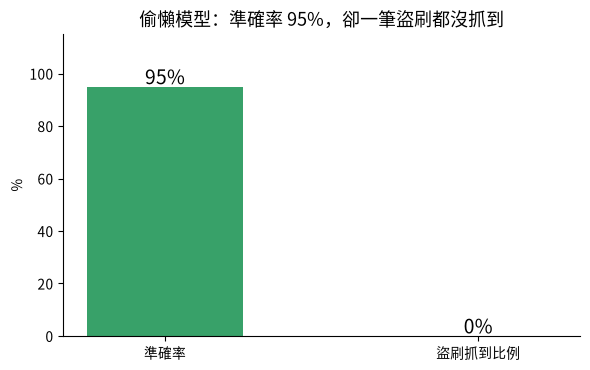

In [5]:
# 學生可以透過 prompt: "建立 95 筆正常、5 筆盜刷的不平衡資料，讓偷懶模型全部預測為正常，計算準確率與抓到的盜刷筆數"
y_true_fraud = [0] * 95 + [1] * 5   # 95 筆正常、5 筆盜刷
y_pred_lazy  = [0] * 100             # 偷懶模型：全部說「正常」

acc_lazy = accuracy_score(y_true_fraud, y_pred_lazy)
caught = sum(t == 1 and p == 1 for t, p in zip(y_true_fraud, y_pred_lazy))

print(f"偷懶模型的準確率：{acc_lazy:.0%}  😲 看起來超厲害？")
print(f"5 筆盜刷抓到幾筆：{caught} 筆      💀 其實完全沒用！")

fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(["準確率", "盜刷抓到比例"], [acc_lazy * 100, caught / 5 * 100], color=[GREEN, RED], width=0.5)
ax.bar_label(bars, labels=[f"{acc_lazy:.0%}", f"{caught / 5:.0%}"], fontsize=14)
ax.set_ylim(0, 115)
ax.set_ylabel("%")
ax.set_title("偷懶模型：準確率 95%，卻一筆盜刷都沒抓到")
plt.tight_layout()
plt.show()

#### 👀 看懂結果
準確率高達 **95%**，但它**一筆盜刷都沒抓到**！原因是資料「**不平衡**」：只要一直猜多數的那一類，準確率就會很高。

👉 所以遇到不平衡資料（盜刷、罕見疾病、瑕疵品…），**不要只看準確率**，要搭配 [精確率](./precision.ipynb)、[召回率](./recall.ipynb) 一起看。

---
## ⚠️ 常見誤區

| 誤區 | 正確觀念 |
| :--- | :--- |
| 準確率越高，模型一定越好 | 資料不平衡時，準確率會「灌水」。先看看每一類各有幾筆！ |
| 準確率 90% 一定很厲害 | 如果 90% 的資料本來就是同一類，**全部猜那一類**就有 90%。 |

---
## ✍️ 隨堂練習

**練習**：把步驟 1 的 `y_pred` 第 4 個值從 `0` 改成 `1`，重新執行步驟 2，準確率變成多少？為什麼？

<details>
<summary>💡 點我看答案</summary>

第 4 封原本是「垃圾信卻猜正常」(FN)，改成猜 1 就猜對了 → 變成 TP。
猜對 9 封 / 10 封 → **準確率 0.90**。

</details>

---
## 📝 重點回顧

| 重點 | 內容 |
| :--- | :--- |
| 公式 | (TP + TN) ÷ 全部 |
| sklearn | `accuracy_score(y_true, y_pred)` |
| 適合 | 各類別數量**差不多**的資料 |
| 小心 | **不平衡資料**會讓準確率看起來很好，其實模型沒用 |
| 下一步 | 👉 [精確率 Precision](./precision.ipynb) |

## 🤖 問問 AI
> 「為什麼在罕見疾病的篩檢中，準確率 99% 的模型可能完全沒有用？請舉一個具體的數字例子。」